# Máquinas de Vectores de Soporte (SVM) con Python y scikit-learn

**Caso de estudio:** clasificar flores del dataset *Iris* en dos especies, **versicolor** vs **virginica**, a partir del largo y el ancho del pétalo. Estas dos especies **se traslapan un poco**, lo que permite ver para qué sirve el **margen blando** de la SVM.

**Objetivo:** mostrar, paso a paso, cómo funciona y cómo se implementa una **SVM** (*Support Vector Machine*), siguiendo todas las etapas de un *pipeline* de Machine Learning, y **compararla (de forma teórica)** con el Perceptrón del tutorial anterior. Todo el código se centra únicamente en la SVM.


## 1. Fundamentos teóricos de la SVM

### 1.1 Origen
La SVM fue desarrollada por **Vladimir Vapnik y colaboradores** (versión moderna con margen blando y *kernels*, 1992–1995) dentro de la **teoría del aprendizaje estadístico**. Durante años fue uno de los clasificadores más usados en la práctica, especialmente con conjuntos de datos pequeños o medianos.

### 1.2 La idea central: no basta con separar, hay que separar *bien*
Igual que el Perceptrón, una SVM lineal busca una **recta** (en 2D), un **plano** (en 3D) o un **hiperplano** (en más dimensiones) que separe dos clases.

Pero si las clases son separables, existen **infinitas rectas válidas**. El Perceptrón se queda con la primera que encuentra. La SVM, en cambio, elige **la mejor**: la que deja **el mayor espacio libre posible** entre la frontera y los puntos más cercanos de cada clase.

> **Analogía:** imagina que debes trazar una carretera entre dos pueblos. Puedes pasar pegado a las casas de uno de ellos, o pasar justo por la mitad con la mayor distancia posible a ambos. La SVM construye la carretera **más ancha** posible.

### 1.3 Conceptos clave

| Concepto | Significado |
|---|---|
| **Hiperplano** | La frontera de decisión (una recta en 2D) |
| **Margen** | La "avenida" libre de puntos a cada lado de la frontera. La SVM busca que sea **lo más ancho posible** |
| **Vectores de soporte** | Los puntos que quedan **sobre el borde del margen** (o dentro de él). Son los únicos que determinan la frontera: si se quitan los demás, la solución no cambia |
| **Margen duro** (*hard margin*) | Exige separar todos los puntos sin error. Solo funciona si las clases son linealmente separables |
| **Margen blando** (*soft margin*) | Tolera que algunos puntos queden dentro del margen o del lado equivocado, a cambio de una penalización. Es lo que se usa en la práctica |
| **Hiperparámetro $C$** | Controla qué tan severa es la penalización por esos errores |
| **Kernel** | Un "truco" que permite trazar fronteras **curvas** sin calcular explícitamente nuevas variables |

### 1.4 El hiperparámetro $C$: el equilibrio entre margen ancho y pocos errores
- **$C$ pequeño** → se tolera más error, el margen es **ancho** y el modelo es más simple (riesgo de *underfitting*).
- **$C$ grande** → se castiga mucho cada error, el margen se **estrecha** para clasificar bien todo el entrenamiento (riesgo de *overfitting*).

### 1.5 Kernels: fronteras no lineales
Cuando los datos no se pueden separar con una recta, la SVM los **proyecta a un espacio de mayor dimensión** donde sí pueden separarse con un hiperplano. El *kernel* hace esa proyección de forma implícita, sin calcular las nuevas coordenadas. Los más comunes:

- **Lineal:** frontera recta.
- **Polinomial:** fronteras curvas de cierto grado.
- **RBF (gaussiano):** fronteras muy flexibles; es el más usado por defecto.

### 1.6 Ventajas y limitaciones
**Ventajas:** frontera única y estable (el problema es convexo, sin mínimos locales), buen desempeño con pocos datos, funciona en espacios de muchas dimensiones, y con kernels resuelve problemas no lineales.

**Limitaciones:** requiere **estandarizar** las variables, es sensible a la elección de $C$ y del kernel, el entrenamiento se vuelve lento con cientos de miles de ejemplos, y no entrega probabilidades de forma directa (solo con un cálculo adicional).

## 2. Modelo matemático

> Se presenta **el modelo** (qué se calcula y qué se optimiza), **sin desarrollo analítico**: no se deduce cómo se resuelve el problema, solo se plantea.

### 2.1 Notación
- Un ejemplo con $d$ características: $\mathbf{x}\in\mathbb{R}^d$ (aquí $d=2$: largo y ancho del pétalo).
- Etiqueta: $y\in\{-1,+1\}$ (en el código usamos 0 y 1; scikit-learn lo convierte internamente).
- Vector de pesos $\mathbf{w}$ y sesgo $b$: definen el hiperplano.

### 2.2 Función de decisión
$$f(\mathbf{x})=\mathbf{w}^\top\mathbf{x}+b$$

La clase predicha es el **signo** de $f(\mathbf{x})$:

$$\hat y=\operatorname{signo}\big(f(\mathbf{x})\big)$$

Es la misma forma que el Perceptrón. **La diferencia está en cómo se eligen $\mathbf{w}$ y $b$.**

### 2.3 Hiperplano y márgenes
- Frontera de decisión: $\;\mathbf{w}^\top\mathbf{x}+b=0$
- Bordes del margen: $\;\mathbf{w}^\top\mathbf{x}+b=+1\;$ y $\;\mathbf{w}^\top\mathbf{x}+b=-1$
- **Ancho del margen:**

$$\text{ancho}=\frac{2}{\|\mathbf{w}\|}$$

Por lo tanto, **un $\mathbf{w}$ más pequeño significa un margen más ancho**.

### 2.4 Problema de optimización: margen duro
Maximizar el margen equivale a minimizar $\|\mathbf{w}\|$:

$$\min_{\mathbf{w},\,b}\;\frac12\|\mathbf{w}\|^2\qquad\text{sujeto a}\qquad y_i(\mathbf{w}^\top\mathbf{x}_i+b)\ge1\quad\forall i$$

La restricción exige que **cada punto** quede del lado correcto y fuera del margen.

### 2.5 Problema de optimización: margen blando
Se introducen **variables de holgura** $\xi_i\ge0$ que miden cuánto viola cada punto el margen:

$$\min_{\mathbf{w},\,b,\,\boldsymbol\xi}\;\frac12\|\mathbf{w}\|^2+C\sum_{i=1}^{m}\xi_i\qquad\text{sujeto a}\qquad y_i(\mathbf{w}^\top\mathbf{x}_i+b)\ge1-\xi_i,\quad\xi_i\ge0$$

El objetivo tiene **dos términos en tensión**:

| Término | Qué busca |
|---|---|
| $\frac12\|\mathbf{w}\|^2$ | Margen **ancho** |
| $C\sum\xi_i$ | **Pocos errores** (penalización total por violaciones) |

$C$ decide cuál pesa más.

### 2.6 Interpretación de $\xi_i$ (holgura)

| Valor de $\xi_i$ | Situación del punto |
|---|---|
| $\xi_i=0$ | Bien clasificado y **fuera** del margen |
| $0<\xi_i\le1$ | Bien clasificado pero **dentro** del margen |
| $\xi_i>1$ | **Mal clasificado** (del lado equivocado) |

### 2.7 Forma equivalente: pérdida *hinge*
El problema anterior es equivalente a minimizar

$$\frac12\|\mathbf{w}\|^2+C\sum_{i=1}^{m}\max\big(0,\;1-y_i(\mathbf{w}^\top\mathbf{x}_i+b)\big)$$

La función $\max(0,\,1-y\,f(\mathbf{x}))$ se llama **pérdida hinge**: vale 0 si el punto está bien clasificado con margen suficiente, y crece linealmente al acercarse o cruzar la frontera.

### 2.8 Forma con vectores de soporte
La solución se puede escribir solo con los **vectores de soporte** (los puntos con $\alpha_i>0$):

$$f(\mathbf{x})=\sum_{i\in SV}\alpha_i\,y_i\,K(\mathbf{x}_i,\mathbf{x})+b$$

donde $K$ es la función **kernel**. Los puntos que no son vectores de soporte tienen $\alpha_i=0$ y **no influyen** en la predicción.

### 2.9 Kernels más usados

| Kernel | $K(\mathbf{x},\mathbf{x}')$ | Frontera |
|---|---|---|
| Lineal | $\mathbf{x}^\top\mathbf{x}'$ | Recta / hiperplano |
| Polinomial | $(\gamma\,\mathbf{x}^\top\mathbf{x}'+r)^{p}$ | Curva de grado $p$ |
| RBF (gaussiano) | $\exp\!\big(-\gamma\|\mathbf{x}-\mathbf{x}'\|^2\big)$ | Curva muy flexible |

En el kernel RBF, $\gamma$ controla la "cercanía": $\gamma$ grande → cada punto influye solo localmente (fronteras muy irregulares, riesgo de sobreajuste); $\gamma$ pequeño → fronteras suaves.

### 2.10 Métricas de evaluación
Con **VP, VN, FP, FN**:

| Métrica | Fórmula |
|---|---|
| Exactitud | $\dfrac{VP+VN}{VP+VN+FP+FN}$ |
| Precisión | $\dfrac{VP}{VP+FP}$ |
| Recall | $\dfrac{VP}{VP+FN}$ |
| $F_1$ | $2\cdot\dfrac{\text{precisión}\cdot\text{recall}}{\text{precisión}+\text{recall}}$ |
| AUC-ROC | Área bajo la curva ROC: probabilidad de que un ejemplo positivo reciba un $f(\mathbf{x})$ mayor que uno negativo |

## 3. Contraste teórico: SVM versus Perceptrón

Ambos son **clasificadores lineales** con la misma función de decisión $\mathbf{w}^\top\mathbf{x}+b$. Lo que cambia es **qué recta eligen** y **cómo aprenden**.

| Aspecto | Perceptrón | SVM |
|---|---|---|
| **Criterio para elegir la frontera** | Cualquier recta que no cometa errores | La que **maximiza el margen** |
| **Si hay infinitas rectas válidas** | Se queda con la primera que encuentra (depende del orden de los datos y de la inicialización) | Siempre la misma: la de mayor margen (solución **única**) |
| **Qué minimiza** | El número de errores (corrección punto por punto) | $\frac12\|\mathbf{w}\|^2+C\sum\xi_i$ (margen ancho + penalización) |
| **Aprendizaje** | Corrige solo cuando se equivoca; actualización por ejemplo | Resuelve un problema de optimización convexa sobre todo el conjunto |
| **Datos no separables** | **Nunca converge**: oscila indefinidamente | Funciona gracias al **margen blando** ($C$) |
| **Puntos que influyen en la frontera** | Todos los que se clasificaron mal durante el entrenamiento | Solo los **vectores de soporte** |
| **Fronteras no lineales** | No puede (falla en XOR) | Sí, mediante **kernels** |
| **Estabilidad** | Resultado cambia con el orden/semilla | Resultado determinista |
| **Pérdida** | Pérdida del Perceptrón: $\max(0,\,-y\,f(\mathbf{x}))$ | Pérdida *hinge*: $\max(0,\,1-y\,f(\mathbf{x}))$ |
| **Hiperparámetros** | Tasa de aprendizaje, épocas | $C$, kernel, $\gamma$ |
| **Coste de entrenamiento** | Muy bajo; escala a datasets enormes | Mayor; se vuelve lento con muchísimos ejemplos |

### La diferencia clave en una línea
Fíjate en las dos pérdidas: el Perceptrón solo se preocupa si el punto está **del lado incorrecto** ($-y\,f>0$). La SVM exige además que los puntos correctos queden **a una distancia mínima** de la frontera (el "$1-$" de la *hinge*). Esa pequeña exigencia extra es lo que produce el margen y la mayor robustez.

## 4. Pipeline de Machine Learning

Etapas que seguiremos:

`Recolección de datos → Descripción/EDA → Scatter plot → Preparación → Selección de hiperparámetros → Entrenamiento → Evaluación → Efecto de C y kernels → Predicción`

### Paso 0. Importar las librerías

In [3]:
# Importamos NumPy: arreglos numéricos y álgebra lineal
import numpy as np
# Importamos pandas: manejo de datos tabulares (DataFrame)
import pandas as pd
# Importamos matplotlib: gráficos
import matplotlib.pyplot as plt
# Importamos load_iris: carga el dataset Iris que viene incluido en scikit-learn
from sklearn.datasets import load_iris as iris
# Importamos las herramientas de partición y validación: train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
# Importamos StandardScaler: estandariza las características (media 0, desviación 1)
from sklearn.preprocessing import StandardScaler
# Importamos SVC: el clasificador SVM de scikit-learn
from sklearn.svm import SVC
# Importamos Pipeline: encadena escalado -> modelo en un solo objeto
from sklearn.pipeline import Pipeline
# Importamos las métricas de clasificación
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

# Fijamos una semilla para que los resultados sean reproducibles
SEED = 42

### 4.1 Recolección de datos

Usamos el dataset **Iris** (Fisher, 1936), incluido en scikit-learn. Nos quedamos con:

- **Clases:** *versicolor* (etiqueta 0) y *virginica* (etiqueta 1).
- **Características:** largo y ancho del pétalo (cm).

A diferencia de setosa vs versicolor (completamente separables), estas dos especies **se traslapan ligeramente**: es un caso realista donde el margen blando de la SVM resulta útil.

In [6]:
# Cargamos el dataset Iris como DataFrame de pandas (as_frame=True incluye los nombres de columnas)
iris = iris(as_frame=True)
# Extraemos la tabla completa (4 características + columna 'target' con la clase 0, 1 o 2)
data = iris.frame
# Nos quedamos con las clases 1 (versicolor) y 2 (virginica)
data = data[data["target"].isin([1, 2])]
# Seleccionamos únicamente largo y ancho del pétalo, más la etiqueta
df = data[["petal length (cm)", "petal width (cm)", "target"]].copy()
# Renombramos las columnas con nombres cortos y sin espacios
df.columns = ["largo_petalo", "ancho_petalo", "clase"]
# Recodificamos las etiquetas a 0 (versicolor) y 1 (virginica)
df["clase"] = df["clase"] - 1
# Reiniciamos el índice para que vaya de 0 a 99
df = df.reset_index(drop=True)
# Mostramos las primeras 5 filas para verificar la carga
df.head()

,largo_petalo,ancho_petalo,clase
0,4.7,1.4,0
1,4.5,1.5,0
2,4.9,1.5,0
3,4.0,1.3,0
4,4.6,1.5,0


### 4.2 Descripción y análisis del dataset (EDA)

In [7]:
# Imprimimos el número de filas y columnas del dataset
print("Dimensiones (filas, columnas):", df.shape)
# Contamos los valores faltantes por columna (esperamos 0)
print("\nValores nulos por columna:\n", df.isnull().sum())
# Contamos cuántos ejemplos hay de cada clase (para ver si las clases están balanceadas)
print("\nEjemplos por clase (0 = versicolor, 1 = virginica):\n", df["clase"].value_counts())

Dimensiones (filas, columnas): (100, 3)

Valores nulos por columna:
 largo_petalo    0
ancho_petalo    0
clase           0
dtype: int64

Ejemplos por clase (0 = versicolor, 1 = virginica):
 clase
0    50
1    50
Name: count, dtype: int64


In [ ]:
# Calculamos estadísticos descriptivos (media, desviación, mínimo, cuartiles, máximo) de las características
df[["largo_petalo", "ancho_petalo"]].describe().round(2)

,largo_petalo,ancho_petalo
count,100.00,100.00
mean,4.91,1.68
std,0.83,0.42
min,3.00,1.00
25%,4.38,1.30
50%,4.90,1.60
75%,5.52,2.00
max,6.90,2.50


In [ ]:
# Calculamos la media y la desviación de cada característica por clase
df.groupby("clase")[["largo_petalo", "ancho_petalo"]].agg(["mean", "std"]).round(2)

largo_petalo       ancho_petalo      
              mean   std         mean   std
clase                                      
0             4.26  0.47         1.33  0.20
1             5.55  0.55         2.03  0.27

In [ ]:
# Calculamos la correlación de Pearson entre todas las columnas (incluida la clase)
df.corr().round(3)

,largo_petalo,ancho_petalo,clase
largo_petalo,1.000,0.823,0.786
ancho_petalo,0.823,1.000,0.828
clase,0.786,0.828,1.000


**Lectura del EDA.**

- El dataset está **balanceado** (50 por clase) y sin valores faltantes, por lo que la exactitud es una métrica razonable.
- Las medias de ambas variables **sí difieren** entre clases, pero las desviaciones son considerables: es de esperarse **cierto traslape** entre las nubes de puntos.
- Largo y ancho del pétalo están **muy correlacionados** entre sí, lo que se verá como una nube alargada en diagonal.

### 4.3 Scatter plot

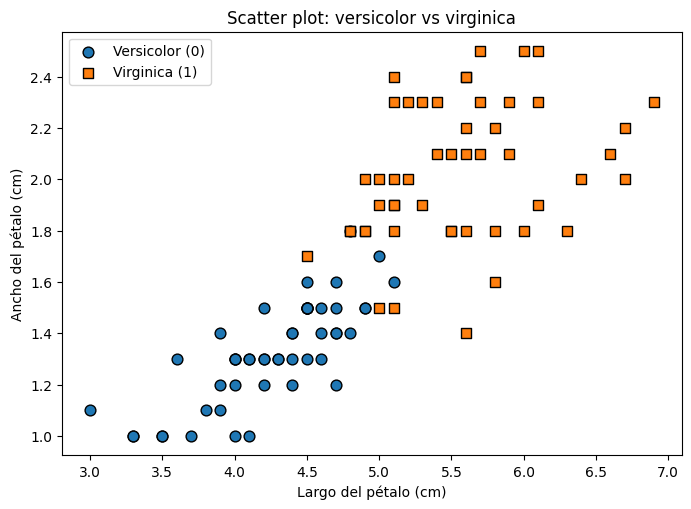

In [8]:
# Creamos una figura de 8x5.5 pulgadas
plt.figure(figsize=(8, 5.5))
# Dibujamos los puntos de versicolor (clase 0)
plt.scatter(df.loc[df["clase"] == 0, "largo_petalo"], df.loc[df["clase"] == 0, "ancho_petalo"],
            color="tab:blue", edgecolor="k", s=60, label="Versicolor (0)")
# Dibujamos los puntos de virginica (clase 1)
plt.scatter(df.loc[df["clase"] == 1, "largo_petalo"], df.loc[df["clase"] == 1, "ancho_petalo"],
            color="tab:orange", edgecolor="k", s=60, marker="s", label="Virginica (1)")
# Etiqueta del eje X
plt.xlabel("Largo del pétalo (cm)")
# Etiqueta del eje Y
plt.ylabel("Ancho del pétalo (cm)")
# Título del gráfico
plt.title("Scatter plot: versicolor vs virginica")
# Mostramos la leyenda
plt.legend()
# Mostramos el gráfico
plt.show()

**Observación:** las dos nubes se ven claramente diferenciadas, pero en la zona central hay **puntos mezclados**. Una recta puede separar casi todos los puntos, aunque quizá no todos: es el escenario típico donde el **margen blando** de la SVM tiene sentido.

### 4.4 Preparación de los datos

1. Separar las características $X$ de la etiqueta $y$.
2. Dividir en **entrenamiento (70 %)** y **prueba (30 %)**, con `stratify=y` para conservar la proporción de clases.

> **El escalado es obligatorio en una SVM:** el margen se mide con distancias, y una variable con escala grande dominaría. Lo incluimos **dentro del Pipeline** para que se calcule solo con el conjunto de entrenamiento (sin *data leakage*).

In [9]:
# X debe ser una matriz 2D (m filas x 2 columnas) con las características
X = df[["largo_petalo", "ancho_petalo"]].values
# y es un vector 1D con la clase de cada flor (0 o 1)
y = df["clase"].values

# Dividimos en entrenamiento (70 %) y prueba (30 %), conservando la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)


### 4.5 Selección del hiperparámetro $C$

$C$ regula el equilibrio entre margen ancho y pocos errores. En lugar de elegirlo "a ojo", probamos varios valores con **validación cruzada de 5 particiones** sobre el conjunto de entrenamiento (`GridSearchCV`) y nos quedamos con el que mejor generaliza.

Empezamos con un kernel **lineal**, el más fácil de interpretar (los kernels no lineales se ven en la sección 4.11).

In [11]:
# Definimos el pipeline base: estandarizar -> SVM con kernel lineal
pipe = Pipeline([
    # Paso 1: estandarizamos las características
    ("scaler", StandardScaler()),
    # Paso 2: SVM con kernel lineal (el valor de C se probará en la búsqueda)
    ("svc", SVC(kernel="linear")),
])

# Definimos la malla de valores de C a probar (de 0.1 a 1000, en escala logarítmica; valores menores se exploran en el bloque siguiente)
param_grid = {"svc__C": [0.1, 1, 10, 100, 1000]}
# Definimos la validación cruzada: 5 particiones estratificadas con semilla fija
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# Creamos la búsqueda: prueba cada C con validación cruzada y mide la exactitud
grid = GridSearchCV(pipe, param_grid, cv=skf, scoring="accuracy")
# Ejecutamos la búsqueda con los datos de entrenamiento
grid.fit(X_train, y_train)

# Organizamos los resultados en una tabla ordenada por C
cv_table = pd.DataFrame({
    # Valor de C probado
    "C": param_grid["svc__C"],
    # Exactitud promedio en validación cruzada
    "exactitud_CV": grid.cv_results_["mean_test_score"].round(4),
    # Desviación estándar entre particiones
    "desv_CV": grid.cv_results_["std_test_score"].round(4),
})
# Mostramos la tabla
print(cv_table.to_string(index=False))
# Mostramos el mejor valor de C encontrado
print("\nMejor C:", grid.best_params_["svc__C"], "| Exactitud CV:", round(grid.best_score_, 4))

     C  exactitud_CV  desv_CV
   0.1        0.9429   0.0535
   1.0        0.9571   0.0350
  10.0        0.9429   0.0286
 100.0        0.9429   0.0286
1000.0        0.9429   0.0286

Mejor C: 1 | Exactitud CV: 0.9571


**Efecto de $C$ sobre el margen.** Para *ver* qué hace $C$, entrenamos el modelo con valores muy distintos (incluidos algunos más pequeños que los de la malla) y medimos el ancho del margen, cuántos puntos terminan siendo vectores de soporte y la exactitud.

In [12]:
# Lista de valores de C a comparar (de muy pequeño a grande)
Cs = [0.001, 0.01, 0.1, 1, 10, 100]
# Lista donde guardaremos una fila de resultados por cada C
filas = []
# Recorremos cada valor de C
for c in Cs:
    # Construimos y entrenamos el pipeline con ese C
    m_c = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="linear", C=c))]).fit(X_train, y_train)
    # Recuperamos la SVM entrenada
    s_c = m_c.named_steps["svc"]
    # Calculamos la exactitud de validación cruzada para ese C
    cv_c = cross_val_score(m_c, X_train, y_train, cv=skf, scoring="accuracy").mean()
    # Guardamos: C, ancho del margen 2/||w||, número de vectores de soporte, exactitud en entrenamiento y en validación cruzada
    filas.append({"C": c, "ancho_margen": round(2 / np.linalg.norm(s_c.coef_[0]), 3),
                  "vectores_soporte": int(s_c.n_support_.sum()),
                  "exactitud_train": round(m_c.score(X_train, y_train), 4),
                  "exactitud_CV": round(cv_c, 4)})
# Mostramos la tabla de resultados
pd.DataFrame(filas)

,C,ancho_margen,vectores_soporte,exactitud_train,exactitud_CV
0,0.001,24.271,70,0.9714,0.9714
1,0.010,3.614,58,0.9571,0.9714
2,0.100,1.885,24,0.9571,0.9429
3,1.000,0.961,12,0.9571,0.9571
4,10.000,0.523,7,0.9714,0.9429
5,100.000,0.467,7,0.9714,0.9429


**Interpretación.** La tabla muestra el mecanismo: con $C$ muy pequeño (0.001) el margen es enorme (≈ 24) y **los 70 puntos son vectores de soporte**, es decir, el modelo casi no distingue nada. Al subir $C$ el margen se estrecha (≈ 0.96 con $C=1$ y ≈ 0.47 con $C=100$) y los vectores de soporte bajan de 70 a 7. La exactitud casi no cambia entre 0.94 y 0.97 porque con solo 70 datos las diferencias son de uno o dos puntos. La validación cruzada elige **$C=1$** (mejor exactitud de validación, 0.957), que además es un punto intermedio razonable: margen amplio y solo 12 vectores de soporte.

### 4.6 Entrenamiento del modelo

Entrenamos el modelo final con el mejor $C$ sobre todo el conjunto de entrenamiento. (`GridSearchCV` ya lo reentrena automáticamente con `refit=True`; aquí lo construimos explícitamente para ver cada pieza.)

In [13]:
# Recuperamos el mejor valor de C hallado por la validación cruzada
C_OPT = grid.best_params_["svc__C"]

# Construimos el pipeline final
model = Pipeline([
    # Paso 1: estandarizamos (parámetros aprendidos solo del conjunto de entrenamiento)
    ("scaler", StandardScaler()),
    # Paso 2: SVM lineal con el C elegido
    ("svc", SVC(kernel="linear", C=C_OPT)),
])

# Entrenamos (ajustamos) el modelo con los datos de entrenamiento
model.fit(X_train, y_train)
# Mostramos la exactitud sobre los datos de entrenamiento
print(f"Exactitud en entrenamiento: {model.score(X_train, y_train):.4f}")

Exactitud en entrenamiento: 0.9571


### 4.7 Parámetros aprendidos y vectores de soporte

Extraemos $\mathbf{w}$, $b$, el ancho del margen $2/\|\mathbf{w}\|$ y los **vectores de soporte**: los únicos puntos que determinan la frontera.

In [14]:
# Recuperamos la SVM entrenada desde el pipeline
svc = model.named_steps["svc"]
# Recuperamos el estandarizador entrenado
scaler = model.named_steps["scaler"]

# Extraemos los pesos w (coef_ tiene forma 1 x 2, por eso tomamos la fila 0); solo existe con kernel lineal
w = svc.coef_[0]
# Extraemos el sesgo b
b = svc.intercept_[0]
# Calculamos el ancho del margen en el espacio estandarizado: 2 / ||w||
ancho_margen = 2 / np.linalg.norm(w)

# Mostramos los pesos aprendidos
print(f"Pesos: w1 (largo) = {w[0]:.4f}, w2 (ancho) = {w[1]:.4f}")
# Mostramos el sesgo
print(f"Sesgo: b = {b:.4f}")
# Mostramos el ancho del margen
print(f"Ancho del margen (2/||w||, en unidades estandarizadas): {ancho_margen:.4f}")
# Mostramos cuántos vectores de soporte hay por clase y en total
print(f"Vectores de soporte por clase: {svc.n_support_} | total: {svc.n_support_.sum()} de {len(X_train)} puntos de entrenamiento")
# Mostramos qué porcentaje de los datos de entrenamiento son vectores de soporte
print(f"Proporción de vectores de soporte: {svc.n_support_.sum() / len(X_train):.1%}")

Pesos: w1 (largo) = 0.9762, w2 (ancho) = 1.8370
Sesgo: b = 0.3828
Ancho del margen (2/||w||, en unidades estandarizadas): 0.9614
Vectores de soporte por clase: [6 6] | total: 12 de 70 puntos de entrenamiento
Proporción de vectores de soporte: 17.1%


**Idea clave:** solo los vectores de soporte definen la frontera. Si eliminaras del entrenamiento cualquier punto que **no** sea vector de soporte y volvieras a entrenar, obtendrías **exactamente la misma recta**. Lo comprobamos:

In [15]:
# Obtenemos los índices (dentro de X_train) de los vectores de soporte
idx_sv = svc.support_
# Estandarizamos X_train con el escalador original (así la comparación no depende de recalcular medias y desviaciones)
Xs_all = scaler.transform(X_train)
# Entrenamos una SVM sobre los puntos YA estandarizados, primero con todos los datos
svc_todos = SVC(kernel="linear", C=C_OPT).fit(Xs_all, y_train)
# Y luego solo con los vectores de soporte
svc_solo_sv = SVC(kernel="linear", C=C_OPT).fit(Xs_all[idx_sv], y_train[idx_sv])
# Comparamos los pesos y el sesgo de ambos modelos
print("Con todos los puntos:       w =", svc_todos.coef_[0].round(4), " b =", svc_todos.intercept_[0].round(4))
# Mostramos los del modelo entrenado solo con vectores de soporte
print("Solo con vectores soporte:  w =", svc_solo_sv.coef_[0].round(4), " b =", svc_solo_sv.intercept_[0].round(4))
# Verificamos numéricamente que coinciden
print("¿Misma frontera?", np.allclose(svc_todos.coef_, svc_solo_sv.coef_, atol=1e-3))

Con todos los puntos:       w = [0.9762 1.837 ]  b = 0.3828
Solo con vectores soporte:  w = [0.9762 1.837 ]  b = 0.3828
¿Misma frontera? True


### 4.8 Evaluación de la técnica (métricas)

Evaluamos con el conjunto de **prueba**, que el modelo no vio durante el entrenamiento.

In [16]:
# Obtenemos las predicciones del modelo sobre el conjunto de prueba
y_pred = model.predict(X_test)
# Obtenemos la función de decisión f(x) = w·x + b (se usa para el AUC)
f_test = model.decision_function(X_test)

# Calculamos la exactitud: proporción de aciertos
acc = accuracy_score(y_test, y_pred)
# Calculamos la precisión de la clase 1 (virginica)
prec = precision_score(y_test, y_pred)
# Calculamos el recall de la clase 1
rec = recall_score(y_test, y_pred)
# Calculamos el F1
f1 = f1_score(y_test, y_pred)
# Calculamos el AUC-ROC usando la función de decisión como puntaje
auc = roc_auc_score(y_test, f_test)

# Armamos una tabla con las métricas
pd.DataFrame({"Métrica": ["Exactitud", "Precisión", "Recall", "F1", "AUC-ROC"],
              "Valor": [acc, prec, rec, f1, auc]}).round(4)

,Métrica,Valor
0,Exactitud,0.8667
1,Precisión,0.9231
2,Recall,0.8000
3,F1,0.8571
4,AUC-ROC,0.9867


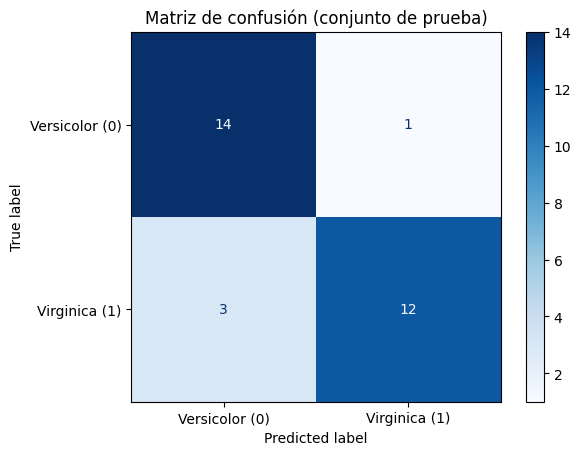

In [17]:
# Calculamos la matriz de confusión: filas = clase real, columnas = clase predicha
cm = confusion_matrix(y_test, y_pred)
# Creamos el objeto de visualización con los nombres de las clases
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Versicolor (0)", "Virginica (1)"])
# Dibujamos la matriz con un mapa de color azul
disp.plot(cmap="Blues")
# Título del gráfico
plt.title("Matriz de confusión (conjunto de prueba)")
# Mostramos el gráfico
plt.show()

In [19]:
# Calculamos la exactitud en cada partición de validación cruzada usando TODO el dataset
cv_acc = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
# Mostramos la exactitud de cada partición
print("Exactitud por partición:", np.round(cv_acc, 4))
# Mostramos el promedio y la desviación estándar
print(f"Exactitud promedio (CV): {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")

Exactitud por partición: [0.9  1.   0.85 0.9  1.  ]
Exactitud promedio (CV): 0.9300 ± 0.0600


**Cómo leer los resultados**

- La **matriz de confusión** tiene los aciertos en la diagonal; fuera de ella están los errores (FP y FN). Aquí es normal ver **algunos errores**, porque las clases se traslapan.
- La **precisión** responde "de los que dije virginica, ¿cuántos lo eran?" y el **recall** "de todas las virginica, ¿cuántas encontré?".
- El **AUC-ROC** mide qué tan bien ordena el modelo a los positivos por encima de los negativos, sin depender de un umbral.
- Con solo 30 datos de prueba, cada error cambia mucho las métricas (en esta partición hubo 4 errores: 1 falso positivo y 3 falsos negativos); por eso la **validación cruzada** da una idea más estable.
- Observa que el **AUC es muy alto** (≈ 0.99) aunque la exactitud sea 0.87: el modelo ordena casi perfectamente las flores por "qué tan virginica es", y los errores se deben sobre todo a que el umbral de decisión (f = 0) cae en la zona de traslape.

### 4.9 Frontera de decisión y margen

Dibujamos la **frontera** ($f(\mathbf{x})=0$, línea continua), los **bordes del margen** ($f(\mathbf{x})=\pm1$, líneas punteadas) y resaltamos los **vectores de soporte** con un círculo grande.

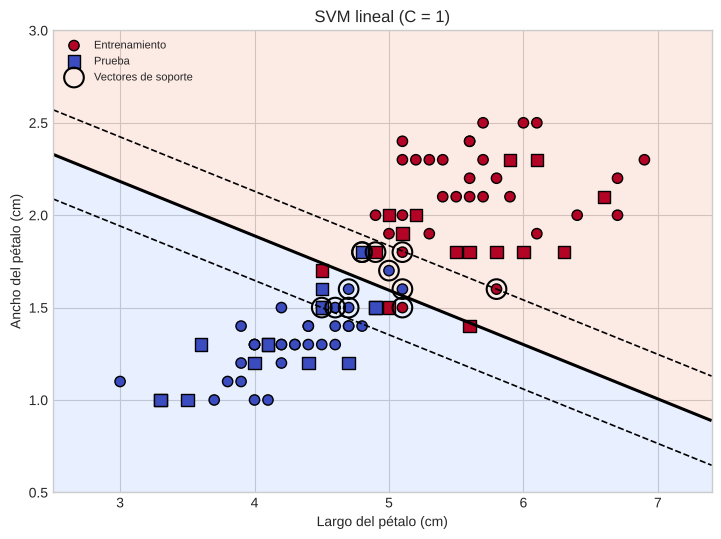

In [ ]:
# Definimos una función reutilizable que dibuja la frontera, el margen, los vectores de soporte y los puntos de una SVM
def graficar_svm(modelo, Xa, ya, ax, titulo, Xt=None, yt=None):
    # Límites del gráfico con un margen de 0.5 cm alrededor de TODOS los datos
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    # Límites del eje Y
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    # Malla de 300 x 300 puntos que cubre el plano
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    # Convertimos la malla en una lista de puntos [largo, ancho]
    grid_pts = np.c_[xx.ravel(), yy.ravel()]
    # Calculamos f(x) en cada punto de la malla y la devolvemos con forma 300 x 300
    ff = modelo.decision_function(grid_pts).reshape(xx.shape)
    # Coloreamos las dos regiones de decisión según el signo de f(x)
    ax.contourf(xx, yy, ff, levels=[-1e9, 0, 1e9], alpha=0.2, cmap="coolwarm")
    # Dibujamos la frontera (f = 0) como línea continua y los bordes del margen (f = -1 y +1) punteados
    ax.contour(xx, yy, ff, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1.2, 2.2, 1.2])
    # Dibujamos los puntos de entrenamiento coloreados por clase
    ax.scatter(Xa[:, 0], Xa[:, 1], c=ya, cmap="coolwarm", edgecolor="k", s=55, label="Entrenamiento")
    # Si se entregó un conjunto de prueba, lo dibujamos con cuadrados
    if Xt is not None:
        ax.scatter(Xt[:, 0], Xt[:, 1], c=yt, cmap="coolwarm", edgecolor="k", s=80, marker="s", label="Prueba")
    # Recuperamos los vectores de soporte (están en el espacio estandarizado)
    sv = modelo.named_steps["svc"].support_vectors_
    # Los devolvemos al espacio original (cm) con la transformación inversa del escalador
    sv = modelo.named_steps["scaler"].inverse_transform(sv)
    # Resaltamos los vectores de soporte con un círculo hueco grande
    ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors="none", edgecolors="k", linewidths=1.5, label="Vectores de soporte")
    # Etiqueta del eje X
    ax.set_xlabel("Largo del pétalo (cm)")
    # Etiqueta del eje Y
    ax.set_ylabel("Ancho del pétalo (cm)")
    # Título del panel
    ax.set_title(titulo)
    # Leyenda
    ax.legend(loc="upper left", fontsize=8)

# Creamos la figura
fig, ax = plt.subplots(figsize=(8.5, 6))
# Dibujamos la SVM lineal entrenada
graficar_svm(model, X_train, y_train, ax, f"SVM lineal (C = {C_OPT})", X_test, y_test)
# Mostramos
plt.show()

**Cómo leer el gráfico:**

- La **línea continua** es la frontera de decisión.
- Las **líneas punteadas** delimitan el margen. Dentro de esa franja puede haber puntos (margen blando).
- Los **círculos grandes** son los vectores de soporte: están sobre los bordes del margen, dentro de él o del lado equivocado. Son los únicos que "sostienen" la frontera.